# Desigualdad de la renta: índice de Gini

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"               # carpeta en research/temas/
GRAFICA_ID = "gini-renta-disponible"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Desigualdad de la renta: índice de Gini"  # `titulo` de la gráfica en config.json
DESDE = 1976                    # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"         # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Índice de Gini de la renta disponible (de 0 a 100)"
CSV_FORMATO = "es"              # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1               # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None               # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None               # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Lo desigual que es el reparto de la **renta disponible** de los hogares (lo que queda después de pagar impuestos directos y cotizaciones y de cobrar prestaciones monetarias, ajustado por el tamaño del hogar) entre las personas. El índice de Gini va de **0** (todas las personas tienen la misma renta) a **100** (una sola persona tiene toda la renta).

**Cómo se lee.** Un valor más alto indica un reparto más desigual. El índice resume toda la distribución en un número: no dice si la desigualdad está arriba (las rentas más altas se alejan) o abajo (las más bajas se quedan atrás); para eso está la gráfica `renta-50-inferior`.

**Limitaciones.**
- Mide la renta, no la riqueza (que está mucho más concentrada; ver `fiscalidad/concentracion-riqueza`).
- No incluye el valor de los servicios públicos (sanidad, educación) ni los impuestos indirectos como el IVA.
- Las encuestas recogen mal las rentas más altas, así que tienden a infraestimar la desigualdad.
- España, la OCDE, EE. UU. y Canadá salen de la OCDE y la UE-27 de Eurostat: son la misma definición de renta, pero con encuestas y criterios de cálculo algo distintos (ver las notas).

## 2. Descarga

- **OCDE, Income Distribution Database** (`OECD.WISE.INE,DSD_WISE_IDD@DF_IDD`, versión 1.0): índice de Gini de la renta disponible (`INC_DISP_GINI`), población total (`AGE=_T`), metodología de 2012 (`METH2012`) y definición vigente (`D_CUR`), para España, EE. UU. y Canadá; el agregado de la OCDE solo si la base lo publica (se comprueba en la descarga). Es el mismo indicador del eje vertical de `presion-fiscal-redistribucion`.
- **Eurostat, encuesta de condiciones de vida** (`ilc_di12`): índice de Gini de la renta disponible equivalente (`GINI_HND`, población total) de la UE-27 (`EU27_2020`) y, solo para las notas, de España.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

from datetime import date

import pandas as pd

from lib import estilos, eurostat, oecd
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, write_grafica_data

HOY = date.today().isoformat()
DATAFLOW_IDD = "OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0"
# Dimensiones: país . frecuencia . medida . operación estadística . unidad . edad . metodología . definición . umbral de pobreza
CLAVE_GINI = "{AREA}.A.INC_DISP_GINI._Z.0_TO_1._T.METH2012.D_CUR._Z"
AREAS = {"ESP": "espana", "USA": "eeuu", "CAN": "canada"}

idd, fuentes = oecd.get(DATAFLOW_IDD, CLAVE_GINI, areas=AREAS, desde=DESDE)
# ¿Publica la IDD el agregado de la OCDE?
try:
    ocde, fuentes_ocde = oecd.get(DATAFLOW_IDD, CLAVE_GINI, areas={"OECD": "ocde"}, desde=DESDE)
except oecd.OecdError as e:
    assert "NoRecordsFound" in str(e), f"OECD: error distinto de «sin datos»: {e}"
    ocde, fuentes_ocde = None, []
print("OCDE publica el agregado:", ocde is not None)

ue, fuentes_ue = eurostat.get("ilc_di12", {"freq": "A", "age": "TOTAL", "statinfo": "GINI_HND"},
                              geos={"EU27_2020": "ue27", "ES": "espana_eurostat"}, desde=DESDE)
print(pd.concat([idd, ue]).groupby("serie")["periodo"].agg(["min", "max", "count"]))

OCDE publica el agregado: False


                  min   max  count
serie                             
canada           1976  2023     48
eeuu             2013  2023     11
espana           2007  2023     17
espana_eurostat  2014  2025     12
ue27             2014  2025     12


## 3. Transformación

1. La OCDE publica el índice de 0 a 1: se multiplica por 100. Eurostat ya lo publica de 0 a 100.
2. La serie `ocde` queda en `null` si la IDD no publica el agregado (sin media propia, METODOLOGIA §2.3).
3. **Año de la renta.** La OCDE fecha cada dato con el año de la renta y Eurostat con el de la encuesta, que pregunta por la renta del año anterior: la serie de Eurostat se adelanta un año para que todas usen el año de la renta.
4. La serie de España de Eurostat no se dibuja (España sale de la OCDE, como EE. UU. y Canadá): solo se usa en las notas para dar la diferencia entre las dos fuentes en el último año común.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


idd = idd.assign(valor=idd["valor"] * 100)
partes = [idd, ue[ue["serie"] == "ue27"]]
if ocde is not None:
    partes.append(ocde.assign(valor=ocde["valor"] * 100))
    fuentes = [*fuentes, *fuentes_ocde]
else:
    partes.append(pd.DataFrame({"serie": ["ocde"], "periodo": [DESDE], "valor": [float("nan")]}))
    fuentes = [*fuentes, FuenteMeta("ocde", oecd.ORGANISMO, f"{DATAFLOW_IDD.split(',')[1]} (consultada: sin agregado OECD)", oecd.URL_EXPLORER, HOY)]
ue = ue.assign(periodo=ue["periodo"] - 1)  # año de la encuesta -> año de la renta, como la OCDE
partes[1] = ue[ue["serie"] == "ue27"]
df = pd.concat(partes, ignore_index=True)
fuentes = [*fuentes, *[f for f in fuentes_ue if f.serie == "ue27"]]

# España en las dos fuentes, en el último año común
oc = idd[idd["serie"] == "espana"].set_index("periodo")["valor"]
eu = ue[ue["serie"] == "espana_eurostat"].set_index("periodo")["valor"]
comunes = sorted(set(oc.index) & set(eu.index))
a = comunes[-1]

_, FLUJO_IDD, VERSION_IDD = DATAFLOW_IDD.split(",")
NOTAS = [
    f"España, Estados Unidos y Canadá: OCDE, Income Distribution Database ({FLUJO_IDD}, versión {VERSION_IDD}): índice de "
    "Gini de la renta disponible equivalente (INC_DISP_GINI), población total, metodología de 2012 y definición vigente "
    "de la renta; la OCDE lo publica de 0 a 1 y aquí se multiplica por 100.",
    "Unión Europea (UE-27): Eurostat, encuesta de condiciones de vida (ilc_di12, GINI_HND), composición actual (EU27_2020). "
    "Eurostat fecha cada dato con el año de la encuesta, que recoge la renta del año anterior; aquí se usa el año de la "
    "renta, como la OCDE (el dato de la encuesta de 2025 aparece en 2024).",
    f"España en las dos fuentes, con el mismo año de renta ({a}): {es(oc[a])} con la OCDE y {es(eu[a])} con Eurostat "
    "(las dos parten de la Encuesta de Condiciones de Vida del INE).",
    ("OCDE: agregado publicado por la OCDE." if ocde is not None else
     "OCDE: sin dato; la Income Distribution Database no publica el agregado de la OCDE y no se calcula una media propia "
     "(METODOLOGIA §2.3)."),
    "No incluye el valor de los servicios públicos (sanidad, educación) ni los impuestos indirectos, y las encuestas "
    "recogen mal las rentas más altas.",
]

## 4. Visualización

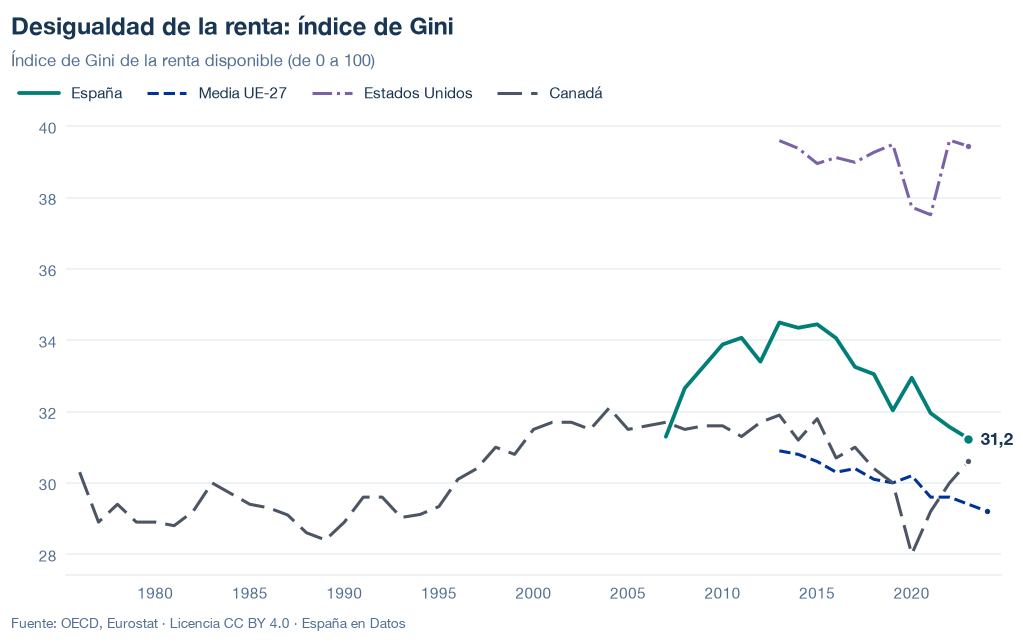

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/gini-renta-disponible.json y data/gini-renta-disponible.csv


## 6. Fuentes, notas y licencia

- OCDE, Income Distribution Database: `OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0` (`INC_DISP_GINI`, `_T`, `METH2012`, `D_CUR`).
- Eurostat, encuesta de condiciones de vida: `ilc_di12` (`GINI_HND`, `TOTAL`).

La fecha de consulta de cada serie está en `fuentes` del JSON; `writer.py` añade a las notas el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.